# Maternal Health Risk Prediction: leakage-safe, calibrated and explainable

**Question:** Using six routine clinical measurements, can we classify a pregnant woman's risk level (low / mid / high), and **how much can we trust the result?**

**Dataset:** [UCI Maternal Health Risk](https://archive.ics.uci.edu/dataset/863/maternal+health+risk) (collected through an IoT-based risk-monitoring system in hospitals and community clinics in rural Bangladesh, according to the UCI description). Features: `Age`, `SystolicBP`, `DiastolicBP`, `BS` (blood sugar, mmol/L), `BodyTemp` (°F), `HeartRate`. Target: `RiskLevel`.

**What this notebook adds beyond "fit a model and report accuracy":**
1. **Duplicate-leakage audit.** Duplicated rows can land in both train and test and inflate scores. We measure how much.
2. **Honest baselines** (majority class, logistic regression) next to tree models.
3. **Clinically relevant metric:** recall for the *high-risk* class (a missed high-risk patient is the costly error), alongside macro-F1.
4. **Calibration and selective prediction:** are the predicted probabilities believable, and can the model say "refer to a doctor" when it is unsure?
5. **Explainability (SHAP)** cross-checked with permutation importance, and a **subgroup check by age**.

> Run top to bottom (**Runtime → Run all**). Nothing here is tuned on the test set. All numbers are printed by the code, none are typed by hand.

## 0. Setup

In [1]:
%pip install -q xgboost shap ucimlrepo

In [2]:
import os, warnings, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from IPython.display import display

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, confusion_matrix, f1_score,
                             log_loss, make_scorer, recall_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
import shap

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)

# colour-blind-safe palette (Okabe-Ito) and a clean plot style
BLUE, ORANGE, GREEN, GREY, RED = "#0072B2", "#D55E00", "#009E73", "#6b7280", "#CC3311"
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 150, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e5e7eb",
                     "axes.axisbelow": True, "legend.frameon": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})

CLASSES = ["low", "mid", "high"]   # ordinal: 0 < 1 < 2
HIGH = 2
RESULTS = {}                        # collected for the final summary

## 1. Load the data
Order of attempts: a local CSV named `Maternal Health Risk Data Set.csv` → download from UCI via `ucimlrepo` → ask you to upload the CSV (Colab).

In [3]:
LOCAL = "Maternal Health Risk Data Set.csv"
EXPECTED = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate", "RiskLevel"]

def load_data():
    if os.path.exists(LOCAL):
        return pd.read_csv(LOCAL), "local file"
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=863)
        return pd.concat([ds.data.features, ds.data.targets], axis=1), "UCI via ucimlrepo"
    except Exception as e:
        print("Automatic download failed:", repr(e)[:200])
    try:
        from google.colab import files
        print("Please upload 'Maternal Health Risk Data Set.csv' (from the UCI dataset page).")
        up = files.upload()
        return pd.read_csv(next(iter(up))), "uploaded file"
    except Exception:
        raise SystemExit("Could not load data. Download the CSV from UCI and place it next to this notebook.")

df_raw, SOURCE = load_data()
missing_cols = [c for c in EXPECTED if c not in df_raw.columns]
assert not missing_cols, f"Unexpected columns, missing: {missing_cols}. Found: {list(df_raw.columns)}"
df_raw = df_raw[EXPECTED].copy()
print("source:", SOURCE, "| shape:", df_raw.shape)
display(df_raw.head())

source: UCI via ucimlrepo | shape: (1014, 7)


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


## 2. Audit the raw data
Before cleaning we measure what is actually wrong, so every cleaning step is justified by evidence.

In [4]:
print("Missing values per column:"); display(df_raw.isna().sum().to_frame("missing").T)
print("Class balance (raw):"); display(df_raw["RiskLevel"].value_counts().to_frame("rows"))
n_dup = int(df_raw.duplicated().sum())
print(f"Exact duplicate rows: {n_dup} of {len(df_raw)} ({100*n_dup/len(df_raw):.1f}%)")
display(df_raw.describe().T[["min", "25%", "50%", "75%", "max"]])

Missing values per column:


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
missing,0,0,0,0,0,0,0


Class balance (raw):


,rows
RiskLevel,
low risk,406
mid risk,336
high risk,272


Exact duplicate rows: 562 of 1014 (55.4%)


,min,25%,50%,75%,max
Age,10.0,19.0,26.0,39.0,70.0
SystolicBP,70.0,100.0,120.0,120.0,160.0
DiastolicBP,49.0,65.0,80.0,90.0,100.0
BS,6.0,6.9,7.5,8.0,19.0
BodyTemp,98.0,98.0,98.0,98.0,103.0
HeartRate,7.0,70.0,76.0,80.0,90.0


**Why duplicates matter:** if the same row appears in both the training and test sets, the model is "tested" on something it has already seen, so the score is optimistic. In medical AI this makes a model look safer than it is. We quantify the effect in section 3b.

## 3. Cleaning
| Step | Why |
|---|---|
| Normalise the label and encode it **ordinally** (low=0, mid=1, high=2) | the classes have a natural order |
| Remove **physiologically impossible** values (plausibility ranges below) | sensor/entry errors; ranges are wide so real patients are never removed |
| Remove **exact duplicate rows** | avoids train/test leakage (section 3b) |

Row-wise rules only: nothing is fitted on the whole data set, so there is no leakage from cleaning.

In [5]:
def encode_label(s):
    s = s.astype(str).str.strip().str.lower()
    out = s.map(lambda v: 0 if v.startswith("low") else 1 if v.startswith("mid") else 2 if v.startswith("high") else np.nan)
    return out

df = df_raw.copy()
df["y"] = encode_label(df["RiskLevel"])
assert df["y"].notna().all(), "Unrecognised RiskLevel values"
df["y"] = df["y"].astype(int)
df = df.drop(columns="RiskLevel")

# plausibility ranges (deliberately generous)
BOUNDS = {"Age": (10, 60), "SystolicBP": (70, 200), "DiastolicBP": (40, 130),
          "BS": (1, 30), "BodyTemp": (90, 108), "HeartRate": (40, 200)}
bad = pd.Series(False, index=df.index)
for col, (lo, hi) in BOUNDS.items():
    mask = (df[col] < lo) | (df[col] > hi)
    print(f"{col:12s} outside [{lo}, {hi}]: {int(mask.sum())}")
    bad |= mask
print("rows with an implausible value:", int(bad.sum()))
df_nobounds = df.loc[~bad].copy()            # keeps duplicates (used for the leakage demo)
df_clean = df_nobounds.drop_duplicates().reset_index(drop=True)

clean_log = {"raw_rows": len(df_raw), "after_plausibility": len(df_nobounds),
             "after_dedup": len(df_clean)}
print(clean_log)
display(df_clean["y"].map(dict(enumerate(CLASSES))).value_counts().to_frame("rows (clean)"))
RESULTS["clean_log"] = clean_log

Age          outside [10, 60]: 8
SystolicBP   outside [70, 200]: 0
DiastolicBP  outside [40, 130]: 0
BS           outside [1, 30]: 0
BodyTemp     outside [90, 108]: 0
HeartRate    outside [40, 200]: 2
rows with an implausible value: 10
{'raw_rows': 1014, 'after_plausibility': 1004, 'after_dedup': 444}


,rows (clean)
y,
low,228
high,110
mid,106


### 3b. How much do duplicates inflate the score?
Same model (Random Forest), same repeated random 80/20 splits, two versions of the data: **with** duplicates and **without**. We also count how many test rows have an exact copy in the training set.

,acc,acc_sd,f1,f1_sd,overlap
with duplicates,0.836,0.022,0.840,0.022,80.6%
duplicates removed,0.637,0.049,0.582,0.051,13.4%


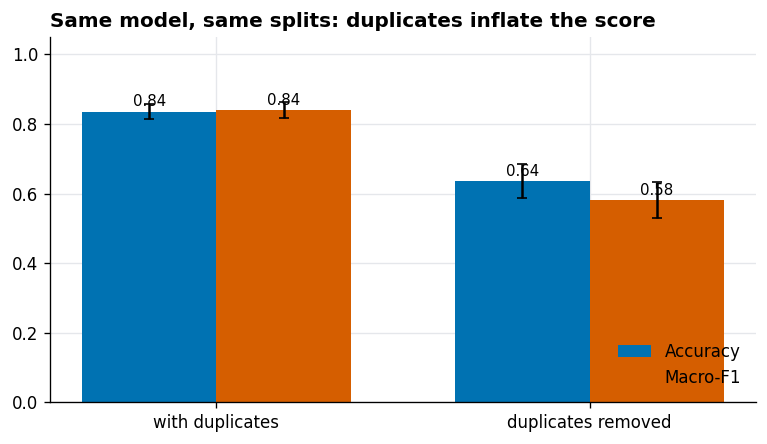

In [6]:
FEATS_RAW = ["Age", "SystolicBP", "DiastolicBP", "BS", "BodyTemp", "HeartRate"]

def split_score(data, n_rep=20):
    accs, f1s, overlaps = [], [], []
    for r in range(n_rep):
        Xtr, Xte, ytr, yte = train_test_split(data[FEATS_RAW], data["y"], test_size=0.2,
                                              stratify=data["y"], random_state=r)
        m = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
        p = m.predict(Xte)
        accs.append(accuracy_score(yte, p)); f1s.append(f1_score(yte, p, average="macro"))
        seen = set(map(tuple, Xtr.values))
        overlaps.append(np.mean([tuple(row) in seen for row in Xte.values]))
    return dict(acc=np.mean(accs), acc_sd=np.std(accs), f1=np.mean(f1s), f1_sd=np.std(f1s),
                overlap=np.mean(overlaps))

leak = {"with duplicates": split_score(df_nobounds), "duplicates removed": split_score(df_clean)}
leak_df = pd.DataFrame(leak).T
display(leak_df.style.format({"acc": "{:.3f}", "acc_sd": "{:.3f}", "f1": "{:.3f}", "f1_sd": "{:.3f}", "overlap": "{:.1%}"}))
RESULTS["leakage"] = leak

fig, ax = plt.subplots(figsize=(6.5, 3.8))
x = np.arange(2); w = 0.36
for i, (name, col) in enumerate([("acc", BLUE), ("f1", ORANGE)]):
    vals = [leak[k][name] for k in leak]; errs = [leak[k][name + "_sd"] for k in leak]
    b = ax.bar(x + (i - 0.5) * w, vals, w, yerr=errs, color=col, capsize=3,
               label="Accuracy" if name == "acc" else "Macro-F1")
    for r_, v in zip(b, vals):
        ax.text(r_.get_x() + r_.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(list(leak)); ax.set_ylim(0, 1.05)
ax.set_title("Same model, same splits: duplicates inflate the score"); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig("figures/fig1_duplicate_leakage.png"); plt.show()

**Reading it:** the gap between the two bars is the optimism caused by duplicates (the `overlap` column shows how many test rows were already in training). **All results below use the de-duplicated data.**

## 4. Feature engineering (row-wise, so leakage-free)
| Feature | Meaning |
|---|---|
| `MAP` = DBP + (SBP − DBP)/3 | mean arterial pressure, average perfusion pressure |
| `PulsePressure` = SBP − DBP | arterial stiffness / cardiac output proxy |
| `ShockIndex` = HR / SBP | haemodynamic stress indicator used in obstetrics |

These are deterministic formulas on each row, so no statistic is learned from the test set. Section 5 checks whether they actually help.

In [7]:
def add_features(d):
    d = d.copy()
    d["MAP"] = d["DiastolicBP"] + (d["SystolicBP"] - d["DiastolicBP"]) / 3
    d["PulsePressure"] = d["SystolicBP"] - d["DiastolicBP"]
    d["ShockIndex"] = d["HeartRate"] / d["SystolicBP"]
    return d

FEATS_ENG = FEATS_RAW + ["MAP", "PulsePressure", "ShockIndex"]
data = add_features(df_clean)
X, y = data[FEATS_ENG], data["y"]

# one hold-out test set, untouched until section 6
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_train.shape, "test:", X_test.shape)
print("class share train:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print("class share test :", y_test.value_counts(normalize=True).sort_index().round(3).to_dict())

train: (355, 9) test: (89, 9)
class share train: {0: 0.513, 1: 0.239, 2: 0.248}
class share test : {0: 0.517, 1: 0.236, 2: 0.247}


## 5. Models and validation (training set only)
Models: **majority-class baseline**, **logistic regression** (scaled), **decision tree**, **random forest**, **XGBoost**.
Validation: **5-fold stratified CV repeated 5 times** (25 scores per model) on the *training* set, so differences can be judged against the spread, not a single lucky split. Metrics: accuracy, **macro-F1**, and **recall of the high-risk class**.

In [8]:
recall_high = make_scorer(lambda yt, yp: recall_score(yt, yp, labels=[HIGH], average="macro", zero_division=0))
SCORING = {"accuracy": "accuracy", "macro_f1": "f1_macro", "recall_high": recall_high}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

def xgb(**kw):
    p = dict(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
             reg_lambda=2.0, objective="multi:softprob", eval_metric="mlogloss",
             random_state=SEED, n_jobs=-1, verbosity=0)
    p.update(kw); return XGBClassifier(**p)

models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "Decision tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1),
    "XGBoost": xgb(),
}
cv_rows, cv_raw = [], {}
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=rcv, scoring=SCORING, n_jobs=-1)
    cv_raw[name] = r
    cv_rows.append({"model": name, **{f"{k}_mean": r[f"test_{k}"].mean() for k in SCORING},
                    **{f"{k}_sd": r[f"test_{k}"].std() for k in SCORING}})
cv_df = pd.DataFrame(cv_rows).set_index("model")
display(cv_df.style.format("{:.3f}"))

,accuracy_mean,macro_f1_mean,recall_high_mean,accuracy_sd,macro_f1_sd,recall_high_sd
model,,,,,,
Majority baseline,0.513,0.226,0.000,0.007,0.002,0.000
Logistic regression,0.672,0.550,0.671,0.042,0.058,0.121
Decision tree,0.693,0.616,0.686,0.037,0.046,0.058
Random forest,0.674,0.604,0.741,0.040,0.045,0.083
XGBoost,0.695,0.630,0.743,0.036,0.046,0.073


### 5b. Do the engineered features help? (ablation)
Same XGBoost, same CV, with only the 6 raw features vs the 9 engineered features.

In [9]:
abl = {}
for label, cols in [("raw 6 features", FEATS_RAW), ("raw + engineered (9)", FEATS_ENG)]:
    r = cross_validate(xgb(), X_train[cols], y_train, cv=rcv, scoring=SCORING, n_jobs=-1)
    abl[label] = {k: (r[f"test_{k}"].mean(), r[f"test_{k}"].std()) for k in SCORING}
abl_df = pd.DataFrame({k: {m: f"{v[0]:.3f} ± {v[1]:.3f}" for m, v in d.items()} for k, d in abl.items()}).T
display(abl_df)
RESULTS["ablation"] = abl

,accuracy,macro_f1,recall_high
raw 6 features,0.705 ± 0.036,0.639 ± 0.048,0.748 ± 0.073
raw + engineered (9),0.695 ± 0.036,0.630 ± 0.046,0.743 ± 0.073


If the two rows overlap within their ± spread, the engineered features are not a measurable gain and the honest conclusion is that tree models already recover these interactions.

### 5c. Light hyper-parameter tuning (inner 5-fold CV on the training set only)
Small grids for the two tree ensembles, scored by macro-F1. The model is **selected by CV score, never by test score**.

In [10]:
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
gs_rf = GridSearchCV(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                     {"min_samples_leaf": [1, 2, 4], "max_depth": [None, 6, 10]},
                     scoring="f1_macro", cv=inner, n_jobs=-1).fit(X_train, y_train)
gs_xgb = GridSearchCV(xgb(), {"max_depth": [2, 3, 4], "n_estimators": [100, 200, 300],
                              "learning_rate": [0.03, 0.1]},
                      scoring="f1_macro", cv=inner, n_jobs=-1).fit(X_train, y_train)
print("RF  best:", gs_rf.best_params_, f"| CV macro-F1 {gs_rf.best_score_:.3f}")
print("XGB best:", gs_xgb.best_params_, f"| CV macro-F1 {gs_xgb.best_score_:.3f}")

tuned = {"Random forest (tuned)": gs_rf.best_estimator_, "XGBoost (tuned)": gs_xgb.best_estimator_}
SELECTED_NAME = max(tuned, key=lambda k: {"Random forest (tuned)": gs_rf.best_score_, "XGBoost (tuned)": gs_xgb.best_score_}[k])
print("Selected by CV:", SELECTED_NAME)

RF  best: {'max_depth': 10, 'min_samples_leaf': 4} | CV macro-F1 0.622
XGB best: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300} | CV macro-F1 0.643
Selected by CV: XGBoost (tuned)


## 6. Final evaluation on the untouched test set
Every model is evaluated **once**. The selected model (chosen by CV above) gets a bootstrap 95% confidence interval, because with a small test set a single number hides a lot of uncertainty.

In [11]:
final_models = {**{k: clone(v).fit(X_train, y_train) for k, v in models.items()}, **tuned}
test_rows, preds = [], {}
for name, m in final_models.items():
    p = m.predict(X_test); preds[name] = p
    test_rows.append({"model": name, "accuracy": accuracy_score(y_test, p),
                      "macro_f1": f1_score(y_test, p, average="macro"),
                      "recall_high": recall_score(y_test, p, labels=[HIGH], average="macro", zero_division=0)})
test_df = pd.DataFrame(test_rows).set_index("model")
display(test_df.style.format("{:.3f}"))

best = final_models[SELECTED_NAME]
rng = np.random.default_rng(SEED)
yt, yp = y_test.values, preds[SELECTED_NAME]
boot = [f1_score(yt[i], yp[i], average="macro") for i in (rng.integers(0, len(yt), len(yt)) for _ in range(1000))]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"\nSelected model: {SELECTED_NAME} | test macro-F1 {f1_score(yt, yp, average='macro'):.3f} (bootstrap 95% CI {lo:.3f} to {hi:.3f}) | n_test = {len(yt)}")
RESULTS.update(test=test_df, selected=SELECTED_NAME, ci=(lo, hi), n_test=len(yt))

,accuracy,macro_f1,recall_high
model,,,
Majority baseline,0.517,0.227,0.000
Logistic regression,0.674,0.557,0.545
Decision tree,0.685,0.604,0.636
Random forest,0.697,0.623,0.636
XGBoost,0.685,0.612,0.591
Random forest (tuned),0.719,0.623,0.727
XGBoost (tuned),0.708,0.622,0.636



Selected model: XGBoost (tuned) | test macro-F1 0.622 (bootstrap 95% CI 0.515 to 0.728) | n_test = 89


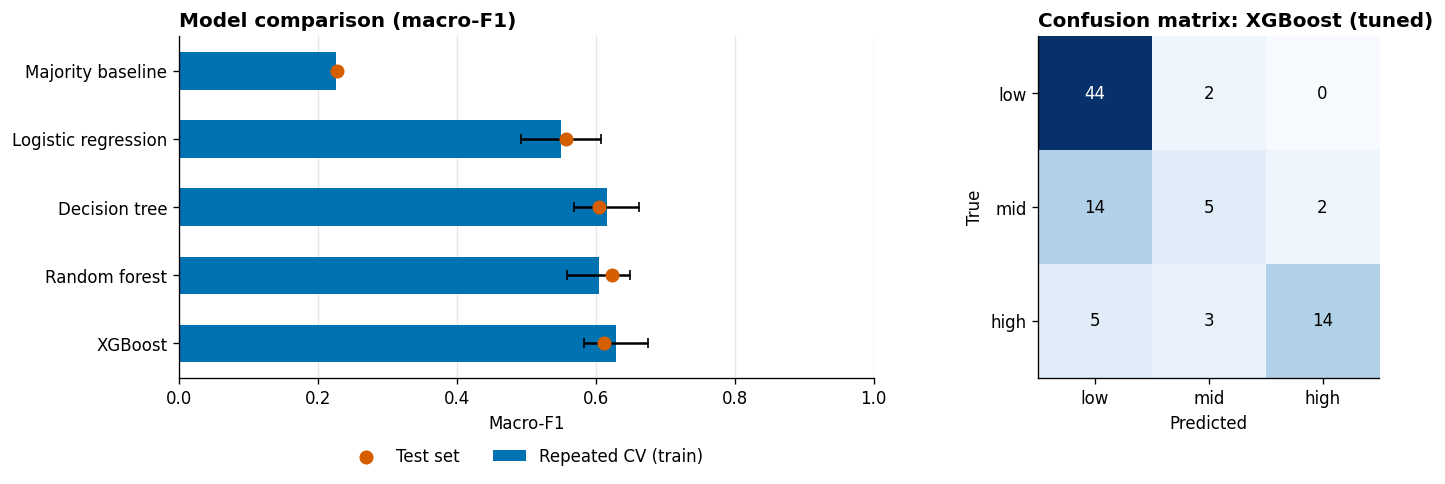

In [12]:
# Figure 2: CV (mean ± sd) vs test macro-F1, and Figure 3: confusion matrix of the selected model
fig, (a, b) = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
names = list(cv_df.index)
a.barh(names, cv_df["macro_f1_mean"], xerr=cv_df["macro_f1_sd"], color=BLUE, capsize=3, height=0.55, label="Repeated CV (train)")
a.scatter([test_df.loc[n, "macro_f1"] for n in names], names, color=ORANGE, zorder=5, s=55, label="Test set")
a.set_xlim(0, 1); a.invert_yaxis(); a.set_xlabel("Macro-F1")
a.set_title("Model comparison (macro-F1)"); a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2); a.grid(axis="y", visible=False)

cm = confusion_matrix(y_test, preds[SELECTED_NAME], labels=[0, 1, 2])
im = b.imshow(cm, cmap="Blues"); b.grid(False)
b.set_xticks(range(3)); b.set_xticklabels(CLASSES); b.set_yticks(range(3)); b.set_yticklabels(CLASSES)
b.set_xlabel("Predicted"); b.set_ylabel("True"); b.set_title(f"Confusion matrix: {SELECTED_NAME}")
for i in range(3):
    for j in range(3):
        b.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.tight_layout(); fig.savefig("figures/fig2_model_comparison_confusion.png"); plt.show()

## 7. Can we trust the probabilities? Calibration and selective prediction
A risk model is only useful clinically if "80% high-risk" really means about 80%. We check the **calibration** of the selected model for the high-risk class, try **sigmoid calibration** (fit on the training set with CV), and then test **selective prediction**: when the model's confidence is low it *abstains* and refers the case to a clinician. We then look at accuracy on the cases it does answer.

,log-loss,Brier (multiclass),accuracy
uncalibrated,0.725,0.430,0.708
sigmoid-calibrated,0.738,0.431,0.708


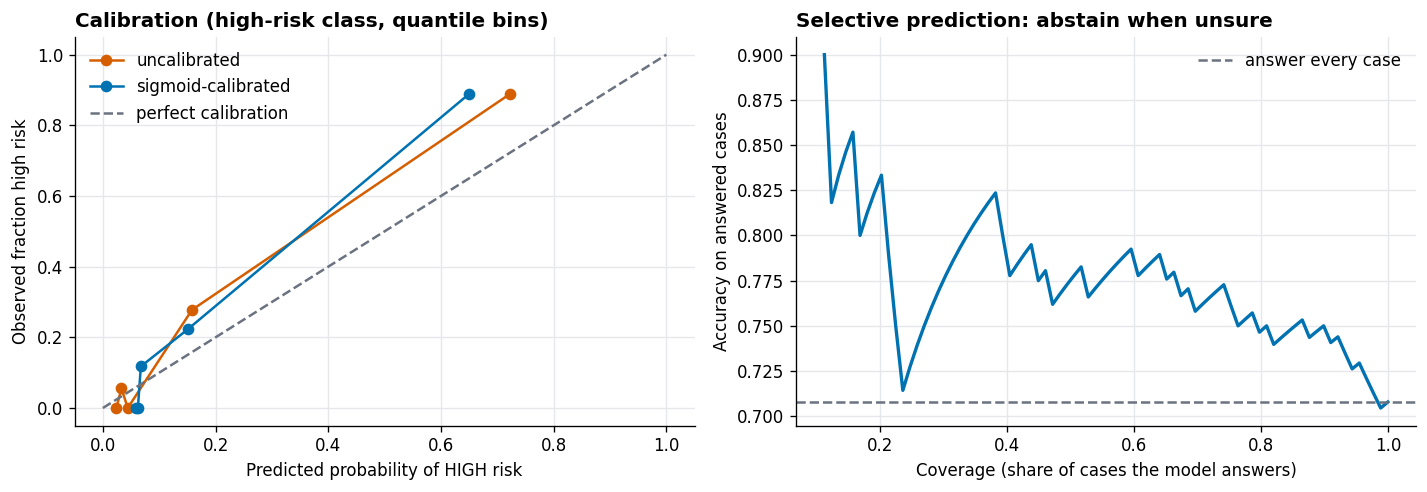

,coverage,accuracy_on_answered
0,0.112,0.900
26,0.404,0.778
53,0.708,0.762
79,1.000,0.708


In [13]:
proba_raw = best.predict_proba(X_test)
cal = CalibratedClassifierCV(clone(best), method="sigmoid", cv=5).fit(X_train, y_train)
proba_cal = cal.predict_proba(X_test)

def brier_multi(y_true, P):
    Y = np.eye(P.shape[1])[y_true]; return np.mean(np.sum((P - Y) ** 2, axis=1))

cal_tbl = pd.DataFrame({
    "log-loss": [log_loss(y_test, proba_raw, labels=[0, 1, 2]), log_loss(y_test, proba_cal, labels=[0, 1, 2])],
    "Brier (multiclass)": [brier_multi(y_test.values, proba_raw), brier_multi(y_test.values, proba_cal)],
    "accuracy": [accuracy_score(y_test, proba_raw.argmax(1)), accuracy_score(y_test, proba_cal.argmax(1))],
}, index=["uncalibrated", "sigmoid-calibrated"])
display(cal_tbl.style.format("{:.3f}"))
RESULTS["calibration"] = cal_tbl

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2))
yb = (y_test.values == HIGH).astype(int)
for P, lab, col in [(proba_raw, "uncalibrated", ORANGE), (proba_cal, "sigmoid-calibrated", BLUE)]:
    fp, mp = calibration_curve(yb, P[:, HIGH], n_bins=5, strategy="quantile")
    a.plot(mp, fp, marker="o", color=col, label=lab)
a.plot([0, 1], [0, 1], ls="--", color=GREY, label="perfect calibration")
a.set_xlabel("Predicted probability of HIGH risk"); a.set_ylabel("Observed fraction high risk")
a.set_title("Calibration (high-risk class, quantile bins)"); a.legend()

P = proba_cal; conf = P.max(1); correct = (P.argmax(1) == y_test.values)
order = np.argsort(-conf); cov, acc_sel = [], []
for k in range(max(10, len(conf) // 10), len(conf) + 1):
    idx = order[:k]; cov.append(k / len(conf)); acc_sel.append(correct[idx].mean())
b.plot(cov, acc_sel, color=BLUE, lw=2)
b.axhline(correct.mean(), color=GREY, ls="--", label="answer every case")
b.set_xlabel("Coverage (share of cases the model answers)"); b.set_ylabel("Accuracy on answered cases")
b.set_title("Selective prediction: abstain when unsure"); b.legend()
fig.tight_layout(); fig.savefig("figures/fig3_calibration_selective.png"); plt.show()

sel = pd.DataFrame({"coverage": cov, "accuracy_on_answered": acc_sel})
display(sel.iloc[[0, len(sel) // 3, 2 * len(sel) // 3, -1]].style.format("{:.3f}"))

**How to read the right plot:** moving left means the model answers fewer cases but is right more often on those. The abstained cases are the ones to send to a clinician. With a small test set the curve is noisy, so treat it as a demonstration of the method, not a deployment threshold.

## 8. Explainability (SHAP) with a cross-check
SHAP (TreeExplainer) explains the **tuned XGBoost** model for the *high-risk* class. To avoid trusting a single method, we compare its feature ranking with **permutation importance** (how much the score drops when a feature is shuffled).

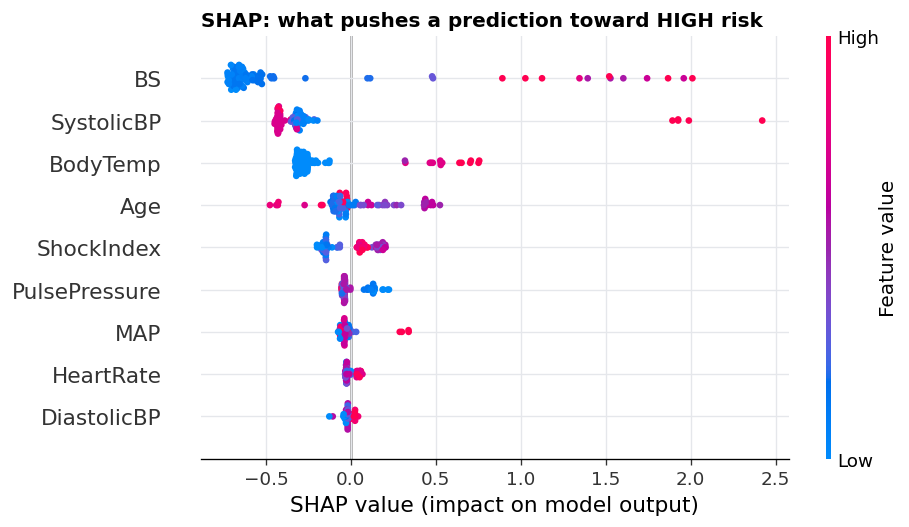

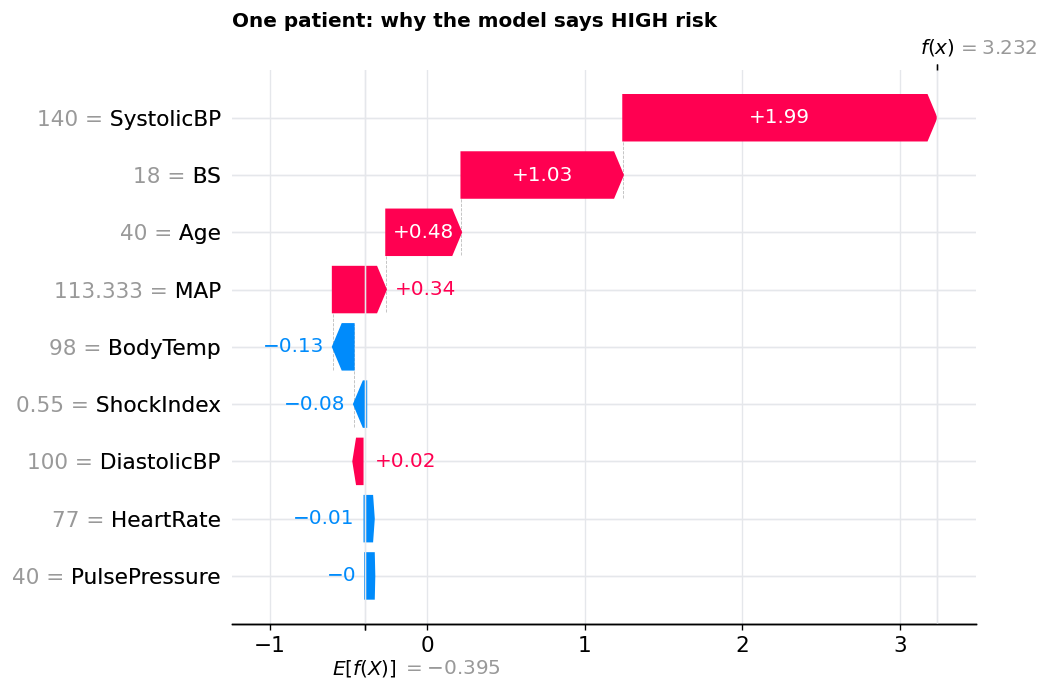

In [14]:
xgb_model = final_models["XGBoost (tuned)"]
explainer = shap.TreeExplainer(xgb_model)
sv = explainer(X_test)
vals, base = sv.values, sv.base_values
if vals.ndim == 3:                       # (rows, features, classes) -> keep the HIGH-risk class
    vals, base = vals[:, :, HIGH], base[:, HIGH]

plt.figure()
shap.summary_plot(vals, X_test, show=False, plot_size=(8, 4.5))
plt.title("SHAP: what pushes a prediction toward HIGH risk", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("figures/fig4_shap_summary.png", bbox_inches="tight"); plt.show()

# local explanation: the test patient the model is most sure is high-risk
i = int(np.argmax(xgb_model.predict_proba(X_test)[:, HIGH]))
shap.plots.waterfall(shap.Explanation(values=vals[i], base_values=base[i],
                                      data=X_test.iloc[i].values, feature_names=list(X_test.columns)), show=False)
plt.title("One patient: why the model says HIGH risk", loc="left", fontweight="bold")
plt.savefig("figures/fig5_shap_waterfall.png", bbox_inches="tight"); plt.show()

In [15]:
shap_rank = pd.Series(np.abs(vals).mean(0), index=X_test.columns, name="mean |SHAP|")
pi = permutation_importance(xgb_model, X_test, y_test, scoring="f1_macro", n_repeats=30, random_state=SEED)
perm = pd.Series(pi.importances_mean, index=X_test.columns, name="permutation importance")
cmp_ = pd.concat([shap_rank, perm], axis=1).sort_values("mean |SHAP|", ascending=False)
display(cmp_.style.format("{:.4f}"))
rho = spearmanr(cmp_["mean |SHAP|"], cmp_["permutation importance"]).correlation
print(f"Spearman rank agreement between SHAP and permutation importance: {rho:.2f}")
RESULTS["shap_perm_rho"] = rho
RESULTS["top_features"] = list(cmp_.index[:3])

,mean |SHAP|,permutation importance
BS,0.7323,0.1867
SystolicBP,0.4490,0.0671
BodyTemp,0.3236,0.0307
Age,0.1505,0.0127
ShockIndex,0.1337,0.0192
PulsePressure,0.0656,0.0147
MAP,0.0512,0.0182
HeartRate,0.0317,0.0138
DiastolicBP,0.0231,0.0063


Spearman rank agreement between SHAP and permutation importance: 0.82


**Caution when interpreting:** SHAP explains *what the model uses*, not *what causes risk*. Correlated features (SBP, DBP, MAP, PulsePressure) share credit, so individual rankings among them are not reliable. A high rank-agreement between the two methods is reassuring, a low one means the explanation should not be over-interpreted.

## 9. Subgroup check by maternal age
Adolescent (<20) and advanced maternal age (≥35) are established risk groups. A model that works on average can still fail on them, so we report performance per age group on the test set. **Group sizes are small, so these numbers are indicative only.**

In [16]:
age = X_test["Age"]
groups = pd.cut(age, bins=[0, 19, 34, 200], labels=["<20", "20-34", ">=35"])
yp_best = best.predict(X_test)
rows = []
for g in ["<20", "20-34", ">=35"]:
    m_ = (groups == g).values
    if m_.sum() == 0:
        continue
    n_high = int((y_test.values[m_] == HIGH).sum())
    rows.append({"age group": g, "n": int(m_.sum()), "n high-risk": n_high,
                 "accuracy": accuracy_score(y_test[m_], yp_best[m_]),
                 "macro-F1": f1_score(y_test[m_], yp_best[m_], average="macro"),
                 "recall (high)": recall_score(y_test[m_], yp_best[m_], labels=[HIGH], average="macro", zero_division=0) if n_high else np.nan})
sub_df = pd.DataFrame(rows).set_index("age group")
display(sub_df.style.format({"accuracy": "{:.3f}", "macro-F1": "{:.3f}", "recall (high)": "{:.3f}"}))
RESULTS["subgroup"] = sub_df

,n,n high-risk,accuracy,macro-F1,recall (high)
age group,,,,,
<20,23,5,0.522,0.394,0.200
20-34,35,6,0.714,0.667,0.667
>=35,31,11,0.839,0.715,0.818


## 10. Summary (generated from the results above)

In [17]:
t = RESULTS["test"]; sel = RESULTS["selected"]; lo, hi = RESULTS["ci"]
L = RESULTS["leakage"]
print("DATA:", RESULTS["clean_log"])
print(f"DUPLICATE LEAKAGE: macro-F1 {L['with duplicates']['f1']:.3f} with duplicates vs {L['duplicates removed']['f1']:.3f} without "
      f"(test rows with an exact training copy: {L['with duplicates']['overlap']:.0%} vs {L['duplicates removed']['overlap']:.0%})")
print(f"SELECTED MODEL (by CV): {sel}")
print(f"TEST (n={RESULTS['n_test']}): accuracy {t.loc[sel,'accuracy']:.3f} | macro-F1 {t.loc[sel,'macro_f1']:.3f} (95% CI {lo:.3f}-{hi:.3f}) | high-risk recall {t.loc[sel,'recall_high']:.3f}")
print(f"BASELINES (test macro-F1): majority {t.loc['Majority baseline','macro_f1']:.3f}, logistic regression {t.loc['Logistic regression','macro_f1']:.3f}")
print("TOP FEATURES (SHAP):", ", ".join(RESULTS["top_features"]), f"| SHAP vs permutation rank agreement {RESULTS['shap_perm_rho']:.2f}")
print("\nLimitations to state in any write-up: small data set, single source, no external validation, "
      "labels come from the data collectors (not independent clinical outcomes), SHAP is not causal.")

DATA: {'raw_rows': 1014, 'after_plausibility': 1004, 'after_dedup': 444}
DUPLICATE LEAKAGE: macro-F1 0.840 with duplicates vs 0.582 without (test rows with an exact training copy: 81% vs 13%)
SELECTED MODEL (by CV): XGBoost (tuned)
TEST (n=89): accuracy 0.708 | macro-F1 0.622 (95% CI 0.515-0.728) | high-risk recall 0.636
BASELINES (test macro-F1): majority 0.227, logistic regression 0.557
TOP FEATURES (SHAP): BS, SystolicBP, BodyTemp | SHAP vs permutation rank agreement 0.82

Limitations to state in any write-up: small data set, single source, no external validation, labels come from the data collectors (not independent clinical outcomes), SHAP is not causal.


In [18]:
# Optional: bundle all figures for download (Colab)
with zipfile.ZipFile("figures.zip", "w") as z:
    for f in sorted(os.listdir("figures")):
        z.write(os.path.join("figures", f))
try:
    from google.colab import files
    files.download("figures.zip")
except Exception:
    print("figures saved in ./figures and ./figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>